# 02 Exploratory data analysis

This notebook explores the cleaned CredData file made by `01_cleaning.ipynb` and the features made by `src/features.py`. The goal is to see which context signals separate real credentials (label 1) from false positives and test values (label 0), before modeling in Phase 2.

The secret values in CredData are random look alikes, and GitHub push protection still treats some of them as real. So this notebook only shows counts, rates and charts, never `LineText` or `Value`.

Every chart is saved to the `images` folder so it can be used in the README and INSIGHTS.

## Setup

We import the libraries, make `src` importable and create the `images` folder. The notebook runs from the `notebooks` folder, so both paths go up one level.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# The notebook runs from the notebooks folder so src and images sit one level up
sys.path.insert(0, str(Path("..") / "src"))
from features import CLEAN_PATH, build_features, load_data

IMAGES = Path("..") / "images"
IMAGES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
LABEL_NAMES = {0: "not real (F or X)", 1: "real (T)"}
PALETTE = {"not real (F or X)": "#8da0cb", "real (T)": "#fc8d62"}


def save(fig, name):
    # Saves every chart the same way so the images folder stays consistent
    fig.tight_layout()
    fig.savefig(IMAGES / name, dpi=120, bbox_inches="tight")
    plt.show()

## Load the data and build the features

`load_data` reads the cleaned file with the agreed settings, and `build_features` turns each row into numeric columns. Both come from `src/features.py`, so 03_preprocessing and Phase 2 use exactly the same features.

In [2]:
print("reading:", CLEAN_PATH.name, "exists:", CLEAN_PATH.exists())
df = load_data()
feats = build_features(df)
print("rows:", len(df), "| raw columns:", df.shape[1], "| feature columns:", feats.shape[1])
print("missing feature values:", int(feats.isna().sum().sum()))
print("share of label 1:", round(df["label"].mean() * 100, 2), "percent")

# One table with the features, the label and a few columns used only for grouping
data = feats.copy()
data["label"] = df["label"]
data["label_name"] = df["label"].map(LABEL_NAMES)
data["GroundTruth"] = df["GroundTruth"]
data["RepoId"] = df["RepoId"]
data["FileExt"] = df["FileExt"].replace("", "(none)")

reading: credata_clean.csv exists: True


rows: 66291 | raw columns: 18 | feature columns: 39
missing feature values: 0
share of label 1: 23.34 percent


## 1. Class balance

`GroundTruth` has three values: T for a real credential, F for a false positive and X for a test value or placeholder. The target `label` groups F and X together as 0.

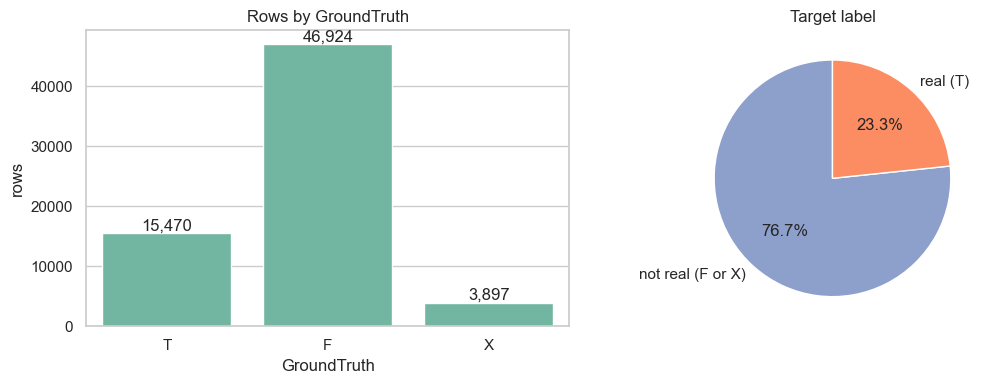

GroundTruth
T    15470
F    46924
X     3897


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
gt_counts = df["GroundTruth"].value_counts().reindex(["T", "F", "X"])
sns.barplot(x=gt_counts.index, y=gt_counts.values, ax=axes[0], color="#66c2a5")
axes[0].set_title("Rows by GroundTruth")
axes[0].set_xlabel("GroundTruth")
axes[0].set_ylabel("rows")
for i, v in enumerate(gt_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

label_counts = data["label_name"].value_counts().reindex(list(LABEL_NAMES.values()))
axes[1].pie(label_counts.values, labels=label_counts.index, autopct="%1.1f%%",
            colors=[PALETTE[n] for n in label_counts.index], startangle=90)
axes[1].set_title("Target label")
save(fig, "01_class_balance.png")

print(gt_counts.to_string())

Real credentials are 23.34 percent of rows (15,470 of 66,291), so the classes are imbalanced and Phase 2 needs class weights or a similar fix. X is small (3,897 rows) next to F (46,924), so the negative class is mostly false positives.

## 2. Repositories

The train and test split is done by repository, so it matters how rows and real secrets are spread across repositories.

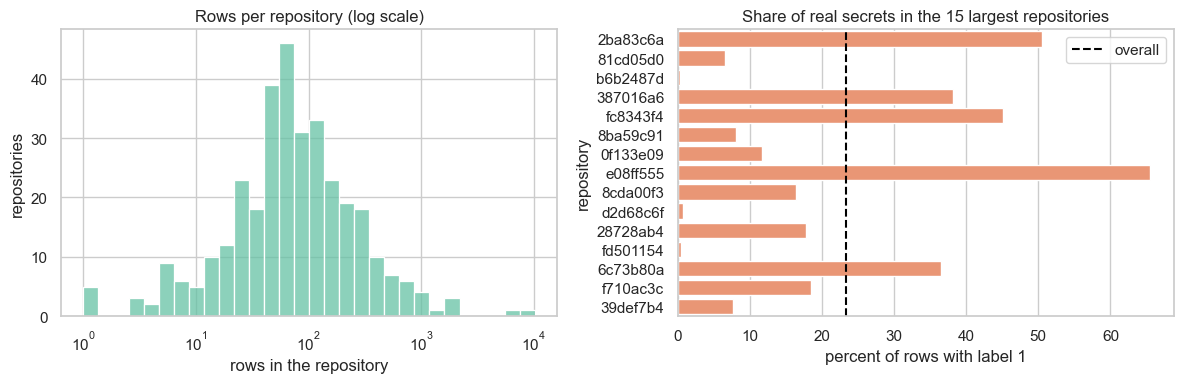

repositories: 335
median rows per repository: 69
share of rows in the 5 largest: 33.32 percent
repositories with no real secret: 24


In [4]:
per_repo = data.groupby("RepoId").agg(rows=("label", "size"), real_share=("label", "mean"))
per_repo = per_repo.sort_values("rows", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per_repo["rows"], log_scale=True, bins=30, ax=axes[0], color="#66c2a5")
axes[0].set_title("Rows per repository (log scale)")
axes[0].set_xlabel("rows in the repository")
axes[0].set_ylabel("repositories")

top = per_repo.head(15)
sns.barplot(x=top["real_share"] * 100, y=top.index, ax=axes[1], color="#fc8d62", orient="h")
axes[1].axvline(data["label"].mean() * 100, color="black", linestyle="--", label="overall")
axes[1].set_title("Share of real secrets in the 15 largest repositories")
axes[1].set_xlabel("percent of rows with label 1")
axes[1].set_ylabel("repository")
axes[1].legend()
save(fig, "02_repositories.png")

print("repositories:", len(per_repo))
print("median rows per repository:", int(per_repo["rows"].median()))
print("share of rows in the 5 largest:", round(per_repo["rows"].head(5).sum() / len(data) * 100, 2), "percent")
print("repositories with no real secret:", int((per_repo["real_share"] == 0).sum()))

The median repository has 69 rows, but the 5 largest hold 33.32 percent of all rows, and 24 of the 335 repositories have no real secret at all. A split by repository can therefore give train and test sets with quite different sizes and label shares, so 03_preprocessing has to check both after the split.

## 3. File types

`src/features.py` groups extensions with a fixed list into code, config, script, doc, keyfile, none and other. We look at how many rows each group has and how often its rows are real secrets, then at the most common single extensions.

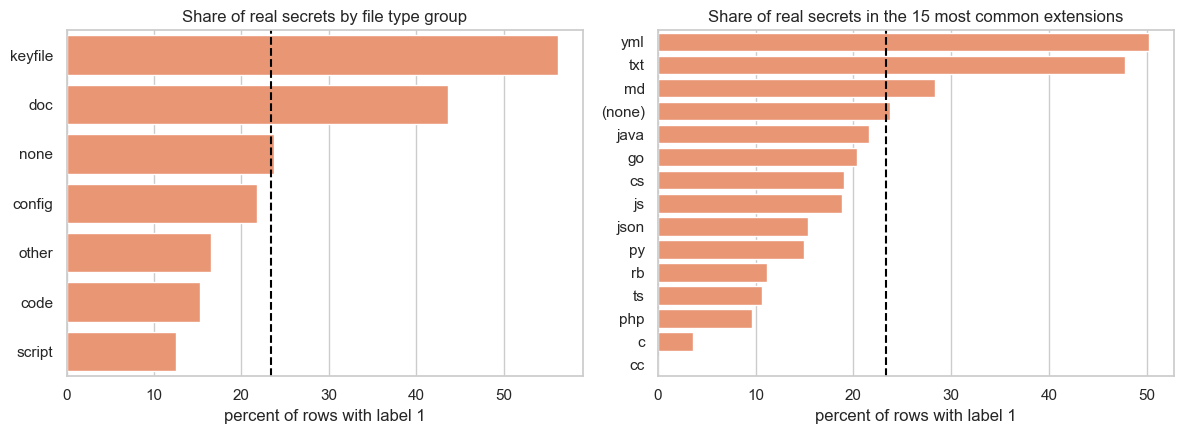

            rows  real_share
ext_group                   
keyfile      306        56.2
doc        14340        43.6
none        1056        23.8
config     15727        21.8
other       5393        16.5
code       28773        15.3
script       696        12.5


In [5]:
ext_cols = [c for c in feats.columns if c.startswith("ext_")]
ext_group = feats[ext_cols].idxmax(axis=1).str.replace("ext_", "", regex=False)
by_group = data.assign(ext_group=ext_group).groupby("ext_group")["label"].agg(rows="size", real_share="mean")
by_group = by_group.sort_values("real_share", ascending=False)

top_ext = data["FileExt"].value_counts().head(15).index
by_ext = data[data["FileExt"].isin(top_ext)].groupby("FileExt")["label"].agg(rows="size", real_share="mean")
by_ext = by_ext.sort_values("real_share", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=by_group["real_share"] * 100, y=by_group.index, ax=axes[0], color="#fc8d62", orient="h")
axes[0].set_title("Share of real secrets by file type group")
sns.barplot(x=by_ext["real_share"] * 100, y=by_ext.index, ax=axes[1], color="#fc8d62", orient="h")
axes[1].set_title("Share of real secrets in the 15 most common extensions")
for ax in axes:
    ax.axvline(data["label"].mean() * 100, color="black", linestyle="--")
    ax.set_xlabel("percent of rows with label 1")
    ax.set_ylabel("")
save(fig, "03_file_types.png")

print(by_group.assign(real_share=(by_group["real_share"] * 100).round(1)).to_string())

Key files are the most likely to hold a real secret (56.2 percent, but only 306 rows). Doc and text files come next at 43.6 percent across 14,340 rows. Source code is the largest group (28,773 rows) but only 15.3 percent of its rows are real, and scripts are lowest at 12.5 percent. So most candidates found in code are false positives, while text files are where real secrets often sit.

## 4. Categories

`Category` says what kind of credential the annotators saw, and one row can have several, separated by a colon. It is not used as a model feature, because a scanner would not know it for new code, but it shows where real secrets come from.

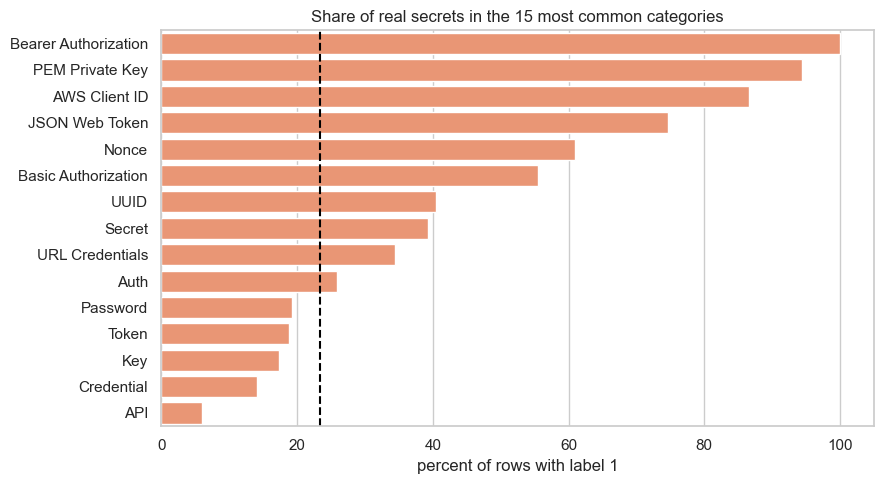

rows with more than one category: 3964
                       rows  real_share
Category                               
Bearer Authorization    289       100.0
PEM Private Key        1263        94.4
AWS Client ID           245        86.5
JSON Web Token          240        74.6
Nonce                   292        61.0
Basic Authorization    1246        55.5
UUID                   6240        40.5
Secret                 3939        39.4
URL Credentials         626        34.3
Auth                   4898        25.9
Password              13600        19.3
Token                  6340        18.8
Key                   24831        17.3
Credential              683        14.1
API                    4153         6.0


In [6]:
cats = df[["Category", "label"]].assign(Category=df["Category"].str.split(":")).explode("Category")
by_cat = cats.groupby("Category")["label"].agg(rows="size", real_share="mean").sort_values("rows", ascending=False).head(15)
by_cat = by_cat.sort_values("real_share", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=by_cat["real_share"] * 100, y=by_cat.index, ax=ax, color="#fc8d62", orient="h")
ax.axvline(data["label"].mean() * 100, color="black", linestyle="--")
ax.set_title("Share of real secrets in the 15 most common categories")
ax.set_xlabel("percent of rows with label 1")
ax.set_ylabel("")
save(fig, "04_categories.png")

print("rows with more than one category:", int(df["Category"].str.contains(":", regex=False).sum()))
print(by_cat.assign(real_share=(by_cat["real_share"] * 100).round(1)).to_string())

Categories with a fixed format are almost always real: Bearer Authorization 100 percent, PEM Private Key 94.4 percent, AWS Client ID 86.5 percent and JSON Web Token 74.6 percent. Generic categories are mostly false positives: Password 19.3 percent, Token 18.8 percent, Key 17.3 percent and API 6.0 percent. Key alone covers 24,831 rows, so generic candidates make up most of the data.

## 5. Value length and entropy

About half the rows have no `Value`, because the whole line is marked or the label spans several lines. We compare those first, then look at length and entropy only on rows that have a value. Entropy is measured in bits per character, and random strings score high.

share of rows with an empty value, by label
label_name
not real (F or X)    62.5
real (T)              9.0


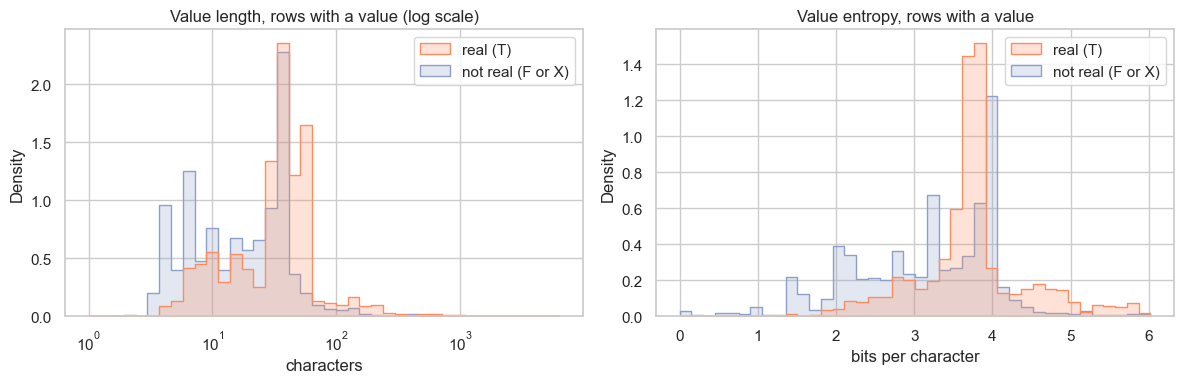

                   value_len  value_entropy
label_name                                 
not real (F or X)       18.0           3.24
real (T)                36.0           3.74


In [7]:
print("share of rows with an empty value, by label")
print((data.groupby("label_name")["value_empty"].mean() * 100).round(1).to_string())

has_value = data[data["value_empty"] == 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=has_value, x="value_len", hue="label_name", palette=PALETTE, log_scale=True,
             stat="density", common_norm=False, element="step", bins=40, ax=axes[0])
axes[0].set_title("Value length, rows with a value (log scale)")
axes[0].set_xlabel("characters")
sns.histplot(data=has_value, x="value_entropy", hue="label_name", palette=PALETTE,
             stat="density", common_norm=False, element="step", bins=40, ax=axes[1])
axes[1].set_title("Value entropy, rows with a value")
axes[1].set_xlabel("bits per character")
for ax in axes:
    ax.get_legend().set_title("")
save(fig, "05_value_length_entropy.png")

print(has_value.groupby("label_name")[["value_len", "value_entropy"]].median().round(2).to_string())

62.5 percent of the not real rows have no value, against 9.0 percent of the real rows. This mostly reflects how F rows were labeled (the whole line marked, with no offsets) rather than anything in the code, so `value_empty` and the value measures that depend on it may leak the labeling process. Phase 2 should test the model with and without them.

On rows that do have a value, real values are longer (median 36 against 18 characters) and more random (median entropy 3.74 against 3.24 bits per character). The values are random look alikes, so this suggests the replacement kept the length and character classes of the original values.

## 6. Character mix of the value

Each ratio is the share of the value made of digits, upper case letters, lower case letters or other symbols.

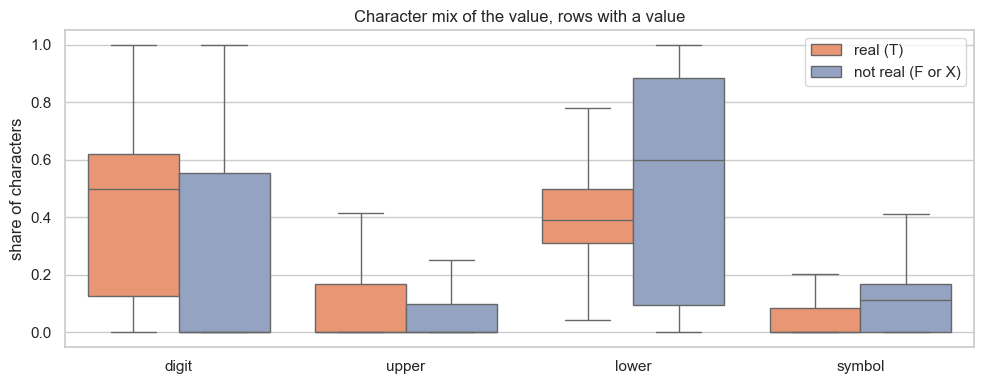

label_name          not real (F or X)  real (T)
value_digit_ratio               0.229     0.391
value_upper_ratio               0.118     0.118
value_lower_ratio               0.526     0.453
value_symbol_ratio              0.127     0.038


In [8]:
ratio_cols = ["value_digit_ratio", "value_upper_ratio", "value_lower_ratio", "value_symbol_ratio"]
long_ratios = has_value.melt(id_vars="label_name", value_vars=ratio_cols, var_name="ratio", value_name="share")
long_ratios["ratio"] = long_ratios["ratio"].str.replace("value_", "").str.replace("_ratio", "")

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=long_ratios, x="ratio", y="share", hue="label_name", palette=PALETTE, showfliers=False, ax=ax)
ax.set_title("Character mix of the value, rows with a value")
ax.set_xlabel("")
ax.set_ylabel("share of characters")
ax.get_legend().set_title("")
save(fig, "06_value_char_mix.png")

print(has_value.groupby("label_name")[ratio_cols].mean().round(3).T.to_string())

Real values contain more digits (39.1 percent against 22.9 percent of characters) and far fewer symbols (3.8 percent against 12.7 percent). Not real values have more lower case letters, which fits placeholders and words. Upper case letters do not differ (11.8 percent in both).

## 7. The labeled line

We look at the length of the labeled line, whether it spans several lines, and how far down the file it sits. Lengths and line numbers are strongly skewed, so the charts use a log scale.

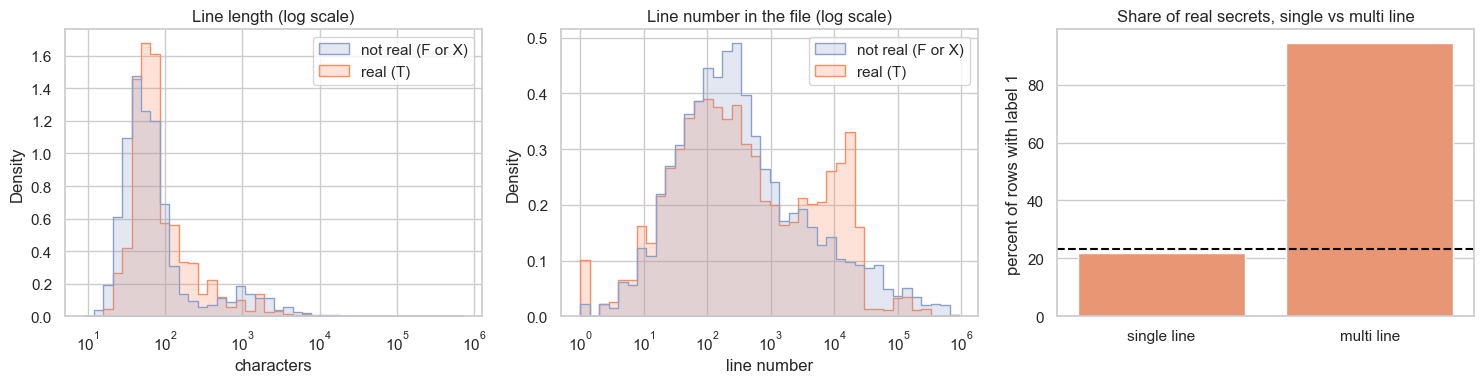

                   line_len  line_number
label_name                              
not real (F or X)      56.0        250.0
real (T)               69.0        276.0
multi line rows: 1347


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=data, x="line_len", hue="label_name", palette=PALETTE, log_scale=True,
             stat="density", common_norm=False, element="step", bins=40, ax=axes[0])
axes[0].set_title("Line length (log scale)")
axes[0].set_xlabel("characters")
sns.histplot(data=data, x="line_number", hue="label_name", palette=PALETTE, log_scale=True,
             stat="density", common_norm=False, element="step", bins=40, ax=axes[1])
axes[1].set_title("Line number in the file (log scale)")
axes[1].set_xlabel("line number")
for ax in axes[:2]:
    ax.get_legend().set_title("")

multi = data.groupby("multi_line")["label"].mean().mul(100).rename({0: "single line", 1: "multi line"})
sns.barplot(x=multi.index, y=multi.values, ax=axes[2], color="#fc8d62")
axes[2].axhline(data["label"].mean() * 100, color="black", linestyle="--")
axes[2].set_title("Share of real secrets, single vs multi line")
axes[2].set_xlabel("")
axes[2].set_ylabel("percent of rows with label 1")
save(fig, "07_line_features.png")

print(data.groupby("label_name")[["line_len", "line_number"]].median().to_string())
print("multi line rows:", int(data["multi_line"].sum()))

Real secrets sit on slightly longer lines (median 69 against 56 characters). The line number barely differs (276 against 250), so position in the file is a weak signal. Multi line labels are rare (1,347 rows) but almost all are real, because they are mostly private keys.

## 8. Keywords and line shape

Each flag is 1 when a pattern appears in the variable name or anywhere in the line. For each flag we compare the share of real secrets on rows where the flag is 1 with the overall share (dashed line). A flag far from the line is a strong signal, as long as it covers enough rows.

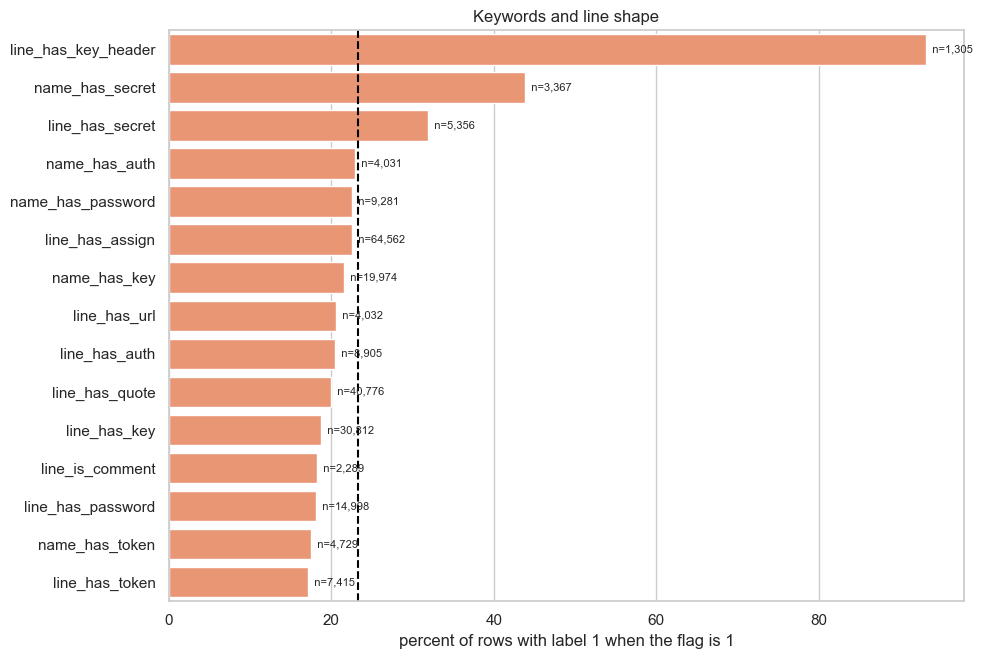

                      rows  real_share
flag                                  
line_has_key_header   1305        93.2
name_has_secret       3367        43.8
line_has_secret       5356        31.9
name_has_auth         4031        23.0
name_has_password     9281        22.6
line_has_assign      64562        22.5
name_has_key         19974        21.5
line_has_url          4032        20.5
line_has_auth         8905        20.4
line_has_quote       40776        20.0
line_has_key         30812        18.8
line_is_comment       2289        18.2
line_has_password    14998        18.2
name_has_token        4729        17.5
line_has_token        7415        17.2


In [10]:
def flag_table(columns):
    # For each 0 or 1 column, the rows where it is 1 and the share of those rows that are real secrets
    rows = []
    for col in columns:
        on = data[col] == 1
        rows.append({"flag": col, "rows": int(on.sum()),
                     "real_share": data.loc[on, "label"].mean() * 100 if on.any() else np.nan})
    return pd.DataFrame(rows).set_index("flag").sort_values("real_share", ascending=False)


def plot_flags(table, title, name):
    fig, ax = plt.subplots(figsize=(10, 0.35 * len(table) + 1.5))
    sns.barplot(x=table["real_share"], y=table.index, ax=ax, color="#fc8d62", orient="h")
    ax.axvline(data["label"].mean() * 100, color="black", linestyle="--")
    for i, (share, n) in enumerate(zip(table["real_share"], table["rows"])):
        ax.text(0 if np.isnan(share) else share, i, f"  n={n:,}", va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("percent of rows with label 1 when the flag is 1")
    ax.set_ylabel("")
    save(fig, name)


line_flags = [c for c in feats.columns if c.startswith(("name_has_", "line_has_", "line_is_"))]
line_table = flag_table(line_flags)
plot_flags(line_table, "Keywords and line shape", "08_keywords.png")
print(line_table.round(1).to_string())

A private key header is the strongest flag: 93.2 percent of its 1,305 rows are real. `secret` in the variable name also helps (43.8 percent). The common keywords do not: `password` in the name is at 22.6 percent and `token` at 17.5 percent, both at or below the overall 23.34 percent. CredData's candidates were found by keyword scanners in the first place, so almost every row already has a keyword, and the keyword alone cannot tell real from fake. `line_has_assign` is 1 on 64,562 rows, so it is almost constant.

## 9. Words in the file path

The same comparison for words in the file path such as test, example, mock and doc. Paths are a common way that tools tell test code from real code.

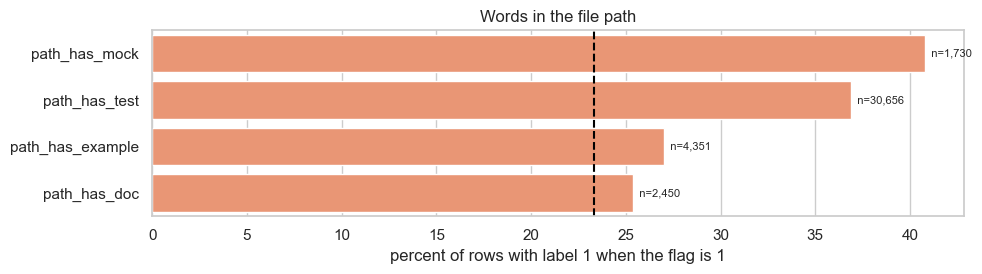

                   rows  real_share
flag                               
path_has_mock      1730        40.8
path_has_test     30656        36.9
path_has_example   4351        27.0
path_has_doc       2450        25.4


In [11]:
path_table = flag_table([c for c in feats.columns if c.startswith("path_has_")])
plot_flags(path_table, "Words in the file path", "09_path_words.png")
print(path_table.round(1).to_string())

Test and mock words in the path go with more real secrets, not fewer: 36.9 percent of rows in test paths and 40.8 percent in mock paths are real, against 23.34 percent overall. So the common rule of ignoring test folders would miss many credentials that CredData labels as real. Example and doc paths are close to the overall share.

## 10. F compared with X

The target puts F (false positive) and X (test value or placeholder) together. This section checks whether they look different, which is one of the open questions in `docs/PROGRESS.md`. We compare them with T on the flags and measures that are most likely to differ.

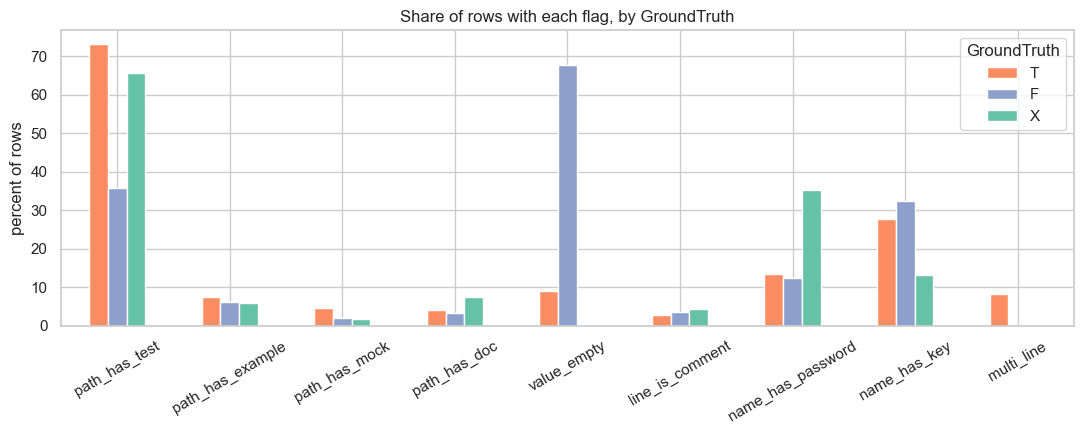

GroundTruth           T     F     X
path_has_test      73.1  35.8  65.5
path_has_example    7.6   6.3   6.0
path_has_mock       4.6   2.0   1.7
path_has_doc        4.0   3.3   7.6
value_empty         9.0  67.7   0.1
line_is_comment     2.7   3.6   4.4
name_has_password  13.6  12.4  35.2
name_has_key       27.8  32.3  13.1
multi_line          8.2   0.2   0.0

             value_len  value_entropy  line_len
GroundTruth                                    
F                  0.0           0.00      58.0
T                 36.0           3.71      69.0
X                  7.0           2.58      40.0


In [12]:
compare_cols = ["path_has_test", "path_has_example", "path_has_mock", "path_has_doc", "value_empty",
                "line_is_comment", "name_has_password", "name_has_key", "multi_line"]
gt_means = data.groupby("GroundTruth")[compare_cols].mean().mul(100).reindex(["T", "F", "X"])

fig, ax = plt.subplots(figsize=(11, 4.5))
gt_means.T.plot(kind="bar", ax=ax, color={"T": "#fc8d62", "F": "#8da0cb", "X": "#66c2a5"})
ax.set_title("Share of rows with each flag, by GroundTruth")
ax.set_ylabel("percent of rows")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
save(fig, "10_f_vs_x.png")

print(gt_means.round(1).T.to_string())
print()
print(data.groupby("GroundTruth")[["value_len", "value_entropy", "line_len"]].median().round(2).to_string())

F and X are different. X almost always has a value (only 0.1 percent empty against 67.7 percent for F), but it is short (median 7 characters) and low in entropy (2.58). X is often named like a password (35.2 percent against 12.4 percent for F) and, like T, mostly sits in test paths (65.5 percent against 35.8 percent for F). So test paths separate F from T and X, not real from fake, and X looks like T in where it is and what it is called, but not in the value itself. The binary label stays as agreed, and GroundTruth stays available for error analysis in Phase 2.

## 11. Correlation between features and with the label

A heatmap of the Spearman correlation between the features and the label. Spearman uses ranks, so the skewed lengths do not dominate. Features that move together carry overlapping information, and the last row shows the link of each feature with the label on its own.

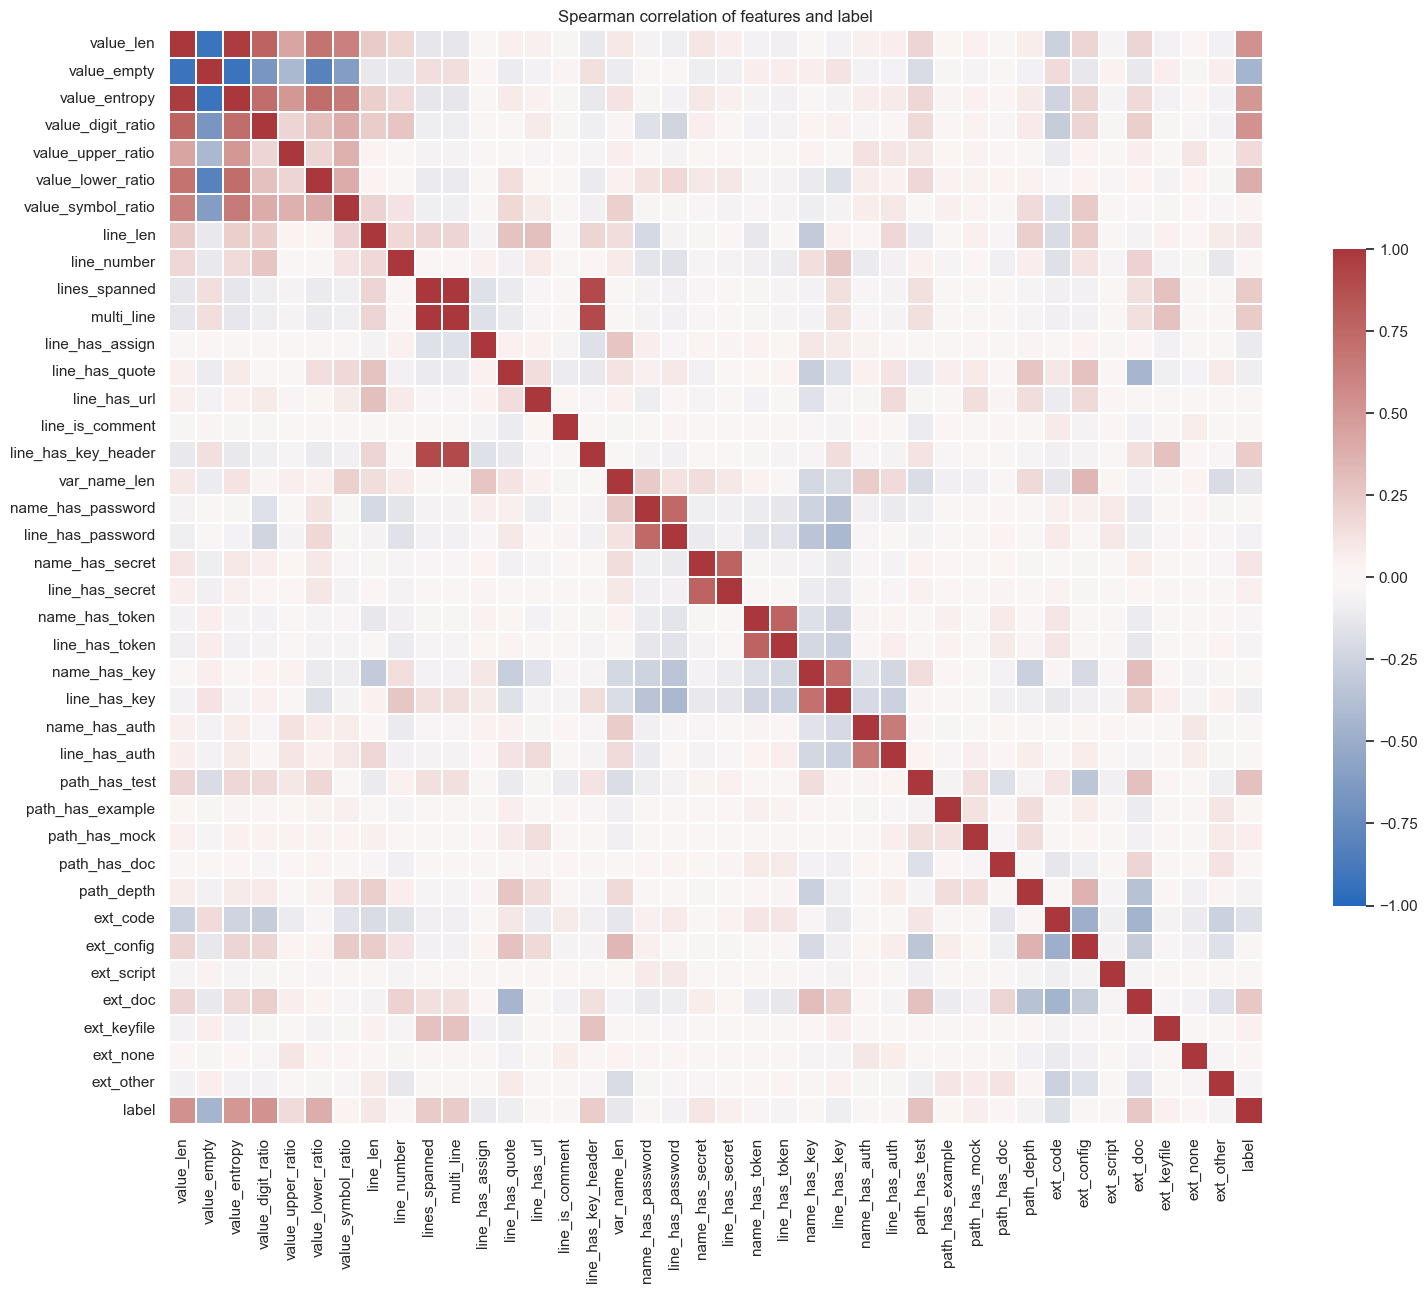

features most linked with the label
value_len              0.531
value_digit_ratio      0.528
value_entropy          0.504
value_empty           -0.453
value_lower_ratio      0.383
path_has_test          0.297
ext_doc                0.251
multi_line             0.242
lines_spanned          0.242
line_has_key_header    0.234
ext_code              -0.167
value_upper_ratio      0.161
var_name_len          -0.129
line_has_assign       -0.117
name_has_secret        0.112

feature pairs with an absolute correlation above 0.8
value_len      value_empty           -0.927
               value_entropy          0.971
value_empty    value_entropy         -0.924
               value_lower_ratio     -0.813
lines_spanned  multi_line             1.000
               line_has_key_header    0.906
multi_line     line_has_key_header    0.905


In [13]:
num = feats.loc[:, feats.nunique() > 1].copy()
num["label"] = data["label"]
corr = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Spearman correlation of features and label")
save(fig, "11_correlation.png")

with_label = corr["label"].drop("label").sort_values(key=abs, ascending=False)
print("features most linked with the label")
print(with_label.head(15).round(3).to_string())
print()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("feature pairs with an absolute correlation above 0.8")
print(pairs[pairs.abs() > 0.8].drop("label", level=1, errors="ignore").round(3).to_string())

The value measures are the most linked with the label: value length 0.531, digit ratio 0.528 and entropy 0.504, with `value_empty` at -0.453. Next come `path_has_test` (0.297), doc files (0.251) and multi line labels (0.242).

Some features carry the same information: value length and entropy correlate at 0.971, and both with `value_empty` at about -0.92. `lines_spanned` and `multi_line` have a rank correlation of 1.0, and both are about 0.9 with the private key header. A model can drop one of each pair without losing information.

## Summary

The findings from this notebook are written up in `INSIGHTS.md`, and each chart in `images` has a short note in `images/NOTES.md`.